# 📈 Training Performance Analysis

#### 🔃 Load Liabaries

In [32]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

#### 📊 Import Data

In [33]:
assessments = pd.read_csv("assessments.csv")

In [34]:
courses = pd.read_csv("courses.csv")

In [35]:
assessments.head(5)

,assessment_id,month,course_id,batch,score,attendance_pct
0,1,Jan,C1,Morning,72,90
1,2,Jan,C2,Evening,45,70
2,3,Jan,C3,Morning,65,85
3,4,Jan,C4,Weekend,38,60
4,5,Feb,C1,Evening,80,95


In [36]:
courses.head(5)

,course_id,course,department
0,C1,Excel,Business
1,C2,PowerBI,Business
2,C3,SQL,Technology
3,C4,Python,Technology


#### ℹ️ Basic Information of data

In [42]:
print ("assessments:",assessments.shape)
print ("courses:",courses.shape)

assessments: (13, 6)
courses: (4, 3)


In [37]:
courses.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   course_id   4 non-null      object
 1   course      4 non-null      object
 2   department  4 non-null      object
dtypes: object(3)
memory usage: 228.0+ bytes


In [38]:
assessments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   assessment_id   13 non-null     int64 
 1   month           13 non-null     object
 2   course_id       13 non-null     object
 3   batch           13 non-null     object
 4   score           13 non-null     int64 
 5   attendance_pct  13 non-null     int64 
dtypes: int64(3), object(3)
memory usage: 756.0+ bytes


In [39]:
assessments.describe()

,assessment_id,score,attendance_pct
count,13.000000,13.000000,13.000000
mean,6.923077,60.000000,80.384615
std,3.774068,16.542874,12.446810
min,1.000000,38.000000,60.000000
25%,4.000000,45.000000,70.000000
50%,7.000000,60.000000,82.000000
75%,10.000000,72.000000,90.000000
max,12.000000,90.000000,98.000000


In [23]:
assessments.duplicated().sum()

np.int64(1)

#### 1️⃣ Confirm numeric types for score and attendance_pct.

In [24]:
️⃣print(assessments[['score', 'attendance_pct']].dtypes)

score             int64
attendance_pct    int64
dtype: object


#### 1.2 Remove Duplicate Rows

In [25]:
print ("Before :",len(assessments))
assessments = assessments.drop_duplicates()
print("After:",len(assessments))

Before : 13
After: 12


#### 1.3 Merge Using (Left Join)

In [27]:
merged = assessments.merge(courses, on="course_id" , how="left")

In [28]:
merged

,assessment_id,month,course_id,batch,score,attendance_pct,course,department
0,1,Jan,C1,Morning,72,90,Excel,Business
1,2,Jan,C2,Evening,45,70,PowerBI,Business
2,3,Jan,C3,Morning,65,85,SQL,Technology
3,4,Jan,C4,Weekend,38,60,Python,Technology
4,5,Feb,C1,Evening,80,95,Excel,Business
5,6,Feb,C2,Weekend,55,80,PowerBI,Business
6,7,Feb,C3,Morning,48,75,SQL,Technology
7,8,Feb,C4,Evening,68,88,Python,Technology
8,9,Mar,C1,Weekend,90,98,Excel,Business
9,10,Mar,C2,Morning,60,82,PowerBI,Business


#### 1.3.1  Check Merged Data Cet

In [31]:
merged.shape

(12, 8)

In [29]:
assert len(merged) == 12
assert merged['department'].isna().sum() == 0

print("All course_id values matched.")

All course_id values matched.


#### 2️⃣ Calculate pass_flag 

In [43]:
merged['pass_flag'] = (merged['score'] >= 50).astype(int)

In [44]:
print(merged[['score', 'pass_flag']])

    score  pass_flag
0      72          1
1      45          0
2      65          1
3      38          0
4      80          1
5      55          1
6      48          0
7      68          1
8      90          1
9      60          1
10     75          1
11     42          0


#### 2.1 Create a grouped summary

In [45]:
summary = merged.groupby('department').agg(
    total_assessments=('pass_flag', 'count'),
    passed=('pass_flag', 'sum')
)

summary['pass_rate'] = summary['passed'] / summary['total_assessments'] * 100

print(summary)

            total_assessments  passed  pass_rate
department                                      
Business                    6       5  83.333333
Technology                  6       3  50.000000


#### 2.2 identify the course with the lowest pass rate

In [46]:
course_summary = merged.groupby('course').agg(
    total=('pass_flag', 'count'),
    passed=('pass_flag', 'sum')
)

course_summary['pass_rate'] = (
    course_summary['passed'] / course_summary['total'] * 100
)

print(course_summary)

         total  passed   pass_rate
course                            
Excel        3       3  100.000000
PowerBI      3       2   66.666667
Python       3       1   33.333333
SQL          3       2   66.666667


In [47]:
lowest = course_summary['pass_rate'].idxmin()

print("Lowest pass rate course:", lowest)
print("Passing count:", course_summary.loc[lowest, 'passed'])
print("Total assessments:", course_summary.loc[lowest, 'total'])

Lowest pass rate course: Python
Passing count: 1
Total assessments: 3


####  3️⃣ Montly Avg SCore 

In [48]:
month_order = ['Jan', 'Feb', 'Mar'] # Set In Order

In [49]:
monthly = merged.groupby('month')['score'].mean()
monthly = monthly.reindex(month_order)

#### 📊 Chart

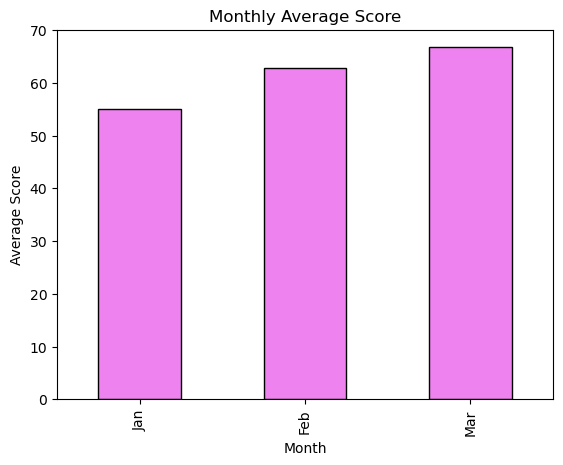

In [55]:
monthly.plot(kind='bar',color = "violet",edgecolor = "black")

plt.title('Monthly Average Score')
plt.xlabel('Month')
plt.ylabel('Average Score')

plt.savefig('outputs/python_chart.png')
plt.show()

##### 3.3 export and clean merged dataset 

In [ ]:
summary.to_csv('outputs5/python_summary.csv')

In [ ]:
merged.to_csv('outputs5/clean_data.csv', index=False)